In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_validate
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
df = pd.read_csv('house_price_train.csv')
print(df.shape)
df.head()

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
print(df['SalePrice'].describe())
print(df.isnull().sum().sort_values(ascending=False).head(10))

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
dtype: int64


In [4]:
features = ['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', '1stFlrSF']
target = 'SalePrice'
print(df[features + [target]].isnull().sum())
print(df[features + [target]].corr()[target].sort_values(ascending=False))

OverallQual    0
GrLivArea      0
GarageCars     0
TotalBsmtSF    0
1stFlrSF       0
SalePrice      0
dtype: int64
SalePrice      1.000000
OverallQual    0.790982
GrLivArea      0.708624
GarageCars     0.640409
TotalBsmtSF    0.613581
1stFlrSF       0.605852
Name: SalePrice, dtype: float64


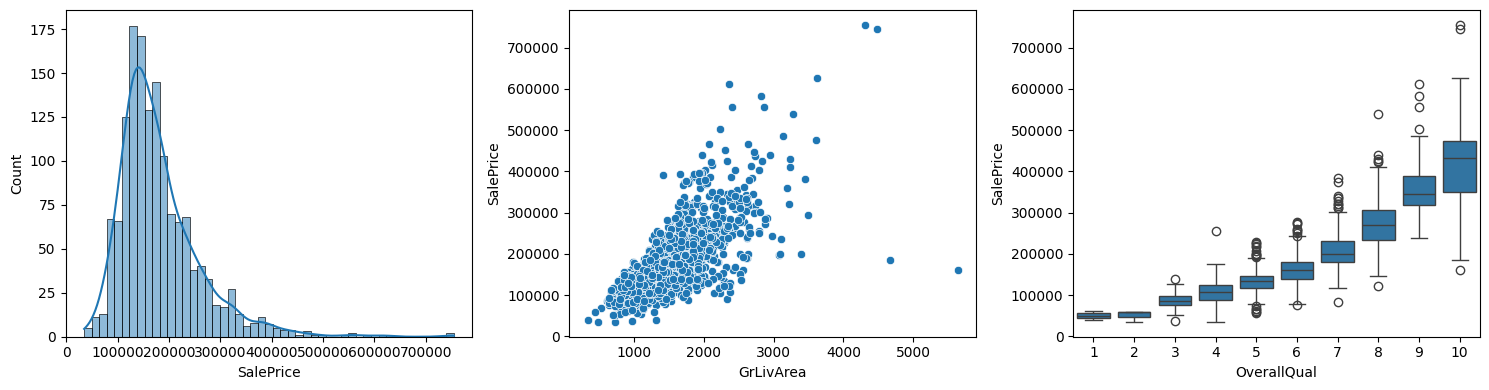

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df['SalePrice'], kde=True, ax=ax[0])
sns.scatterplot(x='GrLivArea', y='SalePrice', data=df, ax=ax[1])
sns.boxplot(x='OverallQual', y='SalePrice', data=df, ax=ax[2])
plt.tight_layout()
plt.show()

In [6]:
X = df[features]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('The test set is kept separate so the final evaluation is done on unseen houses,')
print('giving an unbiased estimate of generalization. Using it during training would cause data leakage.')

Train: (1168, 5) | Test: (292, 5)
The test set is kept separate so the final evaluation is done on unseen houses,
giving an unbiased estimate of generalization. Using it during training would cause data leakage.


In [7]:
model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('rf', RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_split=5, random_state=42))
])
model.fit(X_train, y_train)

rf = model.named_steps['rf']
print('Hyperparameters (set before training):')
print('  n_estimators =', rf.n_estimators)
print('  max_depth =', rf.max_depth)
print('  min_samples_split =', rf.min_samples_split)
print('Parameters (learned during training):')
print('  split features/thresholds in', len(rf.estimators_), 'trees; first tree nodes =', rf.estimators_[0].tree_.node_count)
print('  feature_importances_ =', dict(zip(features, np.round(rf.feature_importances_, 3))))

Hyperparameters (set before training):
  n_estimators = 200
  max_depth = 10
  min_samples_split = 5
Parameters (learned during training):
  split features/thresholds in 200 trees; first tree nodes = 375
  feature_importances_ = {'OverallQual': np.float64(0.608), 'GrLivArea': np.float64(0.204), 'GarageCars': np.float64(0.039), 'TotalBsmtSF': np.float64(0.087), '1stFlrSF': np.float64(0.063)}


In [8]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'MAE:  {mae:,.2f}')
print(f'MSE:  {mse:,.2f}')
print(f'RMSE: {rmse:,.2f}')
print(f'R2:   {r2:.4f}')

MAE:  19,773.58
MSE:  932,732,323.41
RMSE: 30,540.67
R2:   0.8784


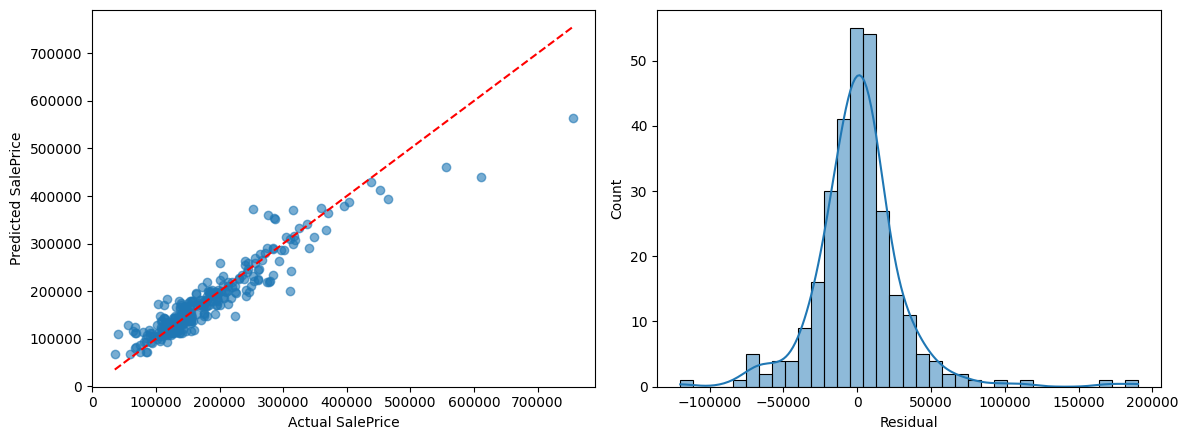

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_test, y_pred, alpha=0.6)
lims = [y_test.min(), y_test.max()]
ax[0].plot(lims, lims, 'r--')
ax[0].set_xlabel('Actual SalePrice')
ax[0].set_ylabel('Predicted SalePrice')
sns.histplot(y_test - y_pred, kde=True, ax=ax[1])
ax[1].set_xlabel('Residual')
plt.tight_layout()
plt.show()

In [10]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

r2_scores = cross_val_score(model, X_train, y_train, cv=kf, scoring='r2')
mae_scores = -cross_val_score(model, X_train, y_train, cv=kf, scoring='neg_mean_absolute_error')
mse_scores = -cross_val_score(model, X_train, y_train, cv=kf, scoring='neg_mean_squared_error')
rmse_scores = np.sqrt(mse_scores)

fold_table = pd.DataFrame({'R2': r2_scores, 'MAE': mae_scores, 'MSE': mse_scores, 'RMSE': rmse_scores},
                          index=[f'Fold {i}' for i in range(1, 6)])
fold_table.loc['Mean'] = fold_table.mean()
fold_table.loc['Std'] = fold_table.iloc[:5].std(ddof=0)
fold_table.round(4)

,R2,MAE,MSE,RMSE
Fold 1,0.8403,21782.3570,1.032369e+09,32130.5018
Fold 2,0.6831,24831.3945,1.854646e+09,43065.6000
Fold 3,0.7966,22763.9412,1.369665e+09,37008.9872
Fold 4,0.8213,21844.8210,9.750830e+08,31226.3186
Fold 5,0.8061,21438.0441,1.022876e+09,31982.4304
Mean,0.7895,22532.1116,1.250928e+09,35082.7676
Std,0.0552,1230.6040,3.329985e+08,4486.3370


In [11]:
comparison = pd.DataFrame({
    'CV Mean': [mae_scores.mean(), mse_scores.mean(), rmse_scores.mean(), r2_scores.mean()],
    'CV Std': [mae_scores.std(), mse_scores.std(), rmse_scores.std(), r2_scores.std()],
    'Test': [mae, mse, rmse, r2],
}, index=['MAE', 'MSE', 'RMSE', 'R2'])
comparison.round(4)

,CV Mean,CV Std,Test
MAE,2.253211e+04,1.230604e+03,1.977358e+04
MSE,1.250928e+09,3.329985e+08,9.327323e+08
RMSE,3.508277e+04,4.486337e+03,3.054067e+04
R2,7.895000e-01,5.520000e-02,8.784000e-01


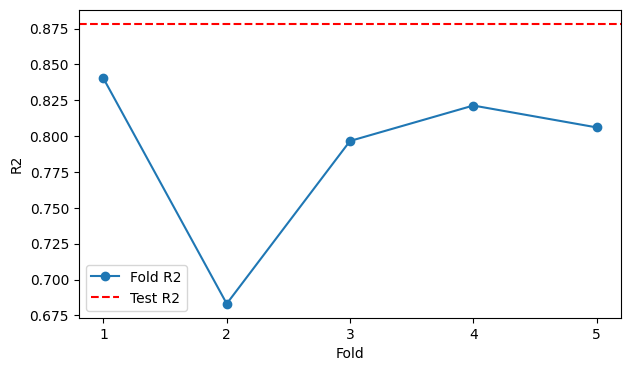

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, 6), r2_scores, 'o-', label='Fold R2')
plt.axhline(r2, color='red', linestyle='--', label='Test R2')
plt.xlabel('Fold')
plt.ylabel('R2')
plt.xticks(range(1, 6))
plt.legend()
plt.show()

In [13]:
gap = abs(r2 - r2_scores.mean())
print(f'CV R2: {r2_scores.mean():.4f} +/- {r2_scores.std():.4f}')
print(f'Test R2: {r2:.4f} (gap = {gap:.4f})')
if r2_scores.std() < 0.05 and gap < 0.05:
    print('Conclusion: The model performs consistently across folds, and CV results agree with the test results.')
else:
    print('Conclusion: Fold scores vary noticeably or differ from the test result, so performance is less consistent.')
print('Cross-validation helps because every training sample is used for validation once; the mean shows expected')
print('performance on unseen houses and the std shows how sensitive the model is to the data split.')

CV R2: 0.7895 +/- 0.0552
Test R2: 0.8784 (gap = 0.0889)
Conclusion: Fold scores vary noticeably or differ from the test result, so performance is less consistent.
Cross-validation helps because every training sample is used for validation once; the mean shows expected
performance on unseen houses and the std shows how sensitive the model is to the data split.
